<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCM · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT149IU · Fundamentals of Programming (Python)</div>

# Lab 5: Sequences – Lists and Tuples

*Indexing and slicing, list methods, sorting and searching, comprehensions, lambdas with filter/map/reduce, 2-D lists and simple visualization*

**Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab, Jupyter Notebook/Lab, VS Code, PyCharm

**How to use this notebook:** read each text cell, run the example cells with **Shift + Enter**, and write your solutions in the cells marked ✍️. Save a copy to your Drive first (*File → Save a copy in Drive*).

> **Legend:** black = original lab content · <font color="#C00000">red = content added in this revision</font>.

<font color="#0070C0">🔵 **[REVISED – Easy2Hard]** Blue text marks what this version adds: a 5-step analysis → algorithm → pseudo-code → code routine, an easy-to-hard task roadmap, warm-up exercises and *stepping-stone* cells. The original content is unchanged.</font>

In [1]:
# Student information – completed for submission
STUDENT_NAME = "Nguyễn Viết Huy"
STUDENT_ID = "ITDSIU24021"
CLASS_GROUP = "IT149IU – Group 01"
print(f"Lab 5 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 5 | Nguyễn Viết Huy | ITDSIU24021 | IT149IU – Group 01


> 📌 **Note** — **<font color="#C00000">Lab plan – 150 minutes (3 periods)</font>**
>
> | <font color="#C00000">Time</font> | <font color="#C00000">Activity</font> |
> |---|---|
> | <font color="#C00000">0 – 10 min</font> | <font color="#C00000">Open the notebook, run the environment check</font> |
> | <font color="#C00000">10 – 35 min</font> | <font color="#C00000">Theory review and worked examples (Sections 3 – 4)</font> |
> | <font color="#C00000">35 – 60 min</font> | <font color="#C00000">Task 1 (slicing), Task 2 (duplicates), Task 3 (insertion sort)</font> |
> | <font color="#C00000">60 – 90 min</font> | <font color="#C00000">Task 4 (guessing game), Task 5 (invoice tuples)</font> |
> | <font color="#C00000">90 – 115 min</font> | <font color="#C00000">Task 6 (user IDs), Task 7 (queue)</font> |
> | <font color="#C00000">115 – 140 min</font> | <font color="#C00000">Tasks 8 – 9 (intro to data science: statistics and dice simulation)</font> |
> | <font color="#C00000">140 – 150 min</font> | <font color="#C00000">Additional exercises 10 – 11 (optional), submit (Section 6)</font> |
>

# 1. Objectives

- Create and initialize lists and tuples.
- Refer to elements of lists, tuples and strings.
- Sort and search lists, and search tuples.
- Pass lists and tuples to functions and methods.
- Use list methods to perform common manipulations, such as searching for items, sorting a list, inserting items and removing items.
- Use additional Python functional-style programming capabilities, including lambdas and the operations filter, map and reduce.
- Use functional-style list comprehensions to create lists quickly and easily, and use generator expressions to generate values on demand.
- Use two-dimensional lists.

# <font color="#C00000">2. Environment Setup</font>

<font color="#C00000">Use any of the environments installed in **Lab 1 (Section 2)**. Quick reference:</font>

| <font color="#C00000">Environment</font> | <font color="#C00000">Install / start</font> | <font color="#C00000">Run code</font> |
|---|---|---|
| <font color="#C00000">Google Colab (recommended)</font> | <font color="#C00000">https://colab.research.google.com → *File → Upload notebook* → `FoP_Lab5.ipynb` → *File → Save a copy in Drive*</font> | <font color="#C00000">`Shift + Enter` in a cell; *Runtime → Run all*</font> |
| <font color="#C00000">Visual Studio Code</font> | <font color="#C00000">Install Python 3.12+, VS Code, and the *Python* + *Jupyter* extensions; select the interpreter with `Ctrl+Shift+P` → *Python: Select Interpreter*</font> | <font color="#C00000">▶ *Run Python File*, `Ctrl+F5`, or `python file.py` in the terminal; notebooks: *Run All*</font> |
| <font color="#C00000">PyCharm</font> | <font color="#C00000">*New Project → Pure Python* (virtualenv, Python 3.12+); packages via *Settings → Project → Python Interpreter → +*</font> | <font color="#C00000">Right-click → *Run 'file'* (`Ctrl+Shift+F10` / `Ctrl+Shift+R` on Mac)</font> |
| <font color="#C00000">JupyterLab</font> | <font color="#C00000">`pip install jupyterlab` → `jupyter lab`</font> | <font color="#C00000">`Shift + Enter`; *Kernel → Restart Kernel and Run All Cells*</font> |
| <font color="#C00000">Jupyter Notebook</font> | <font color="#C00000">`pip install notebook` → `jupyter notebook`</font> | <font color="#C00000">`Shift + Enter`; *Kernel → Restart & Run All*</font> |

<font color="#C00000">**Packages used in this lab:** numpy, matplotlib, seaborn (Tasks 8 – 9)</font>

<font color="#C00000">*(added)*</font>
```bash
# Desktop IDEs (run once in a terminal / inside your virtual environment)
pip install numpy matplotlib seaborn
# Google Colab: these packages are pre-installed – no action needed
```

In [2]:
# [ADDED] worked example – run this cell
# Environment check – run this cell first
import sys
print("Python", sys.version.split()[0])
import numpy as np, matplotlib, seaborn as sns; print("numpy", np.__version__, "| seaborn", sns.__version__)

Python 3.13.5


numpy 2.3.5 | seaborn 0.13.2


# <font color="#C00000">3. Theory</font>

## <font color="#C00000">3.1 Lists vs. tuples</font>

| <font color="#C00000"></font> | <font color="#C00000">List</font> | <font color="#C00000">Tuple</font> |
|---|---|---|
| <font color="#C00000">Syntax</font> | <font color="#C00000">`[1, 2, 3]`</font> | <font color="#C00000">`(1, 2, 3)` or `1, 2, 3`</font> |
| <font color="#C00000">Mutable?</font> | <font color="#C00000">yes – items can be changed, added, removed</font> | <font color="#C00000">no – immutable</font> |
| <font color="#C00000">Typical use</font> | <font color="#C00000">a collection of similar items that changes</font> | <font color="#C00000">a fixed record, e.g. `('83', 'Electric sander', 7, 57.98)`</font> |

### Lists and tuples
- `[]` creates a list, which is mutable (items can be changed).
- `()` creates a tuple, which is immutable (items cannot be reassigned).
- A vector is a mathematical concept; a Python tuple is one way to store a fixed sequence, but the two terms are not identical.

In [3]:
list_of_days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
print(list_of_days)

['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']


In [4]:
list_of_days[1]= "Tuesday"

In [5]:
print(list_of_days)

['Mon', 'Tuesday', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']


In [6]:
a = (1, 2, 3, 7)
print(a)

(1, 2, 3, 7)


In [7]:
# Tuples are immutable. Catch and display the expected exception so the notebook can run top-to-bottom.
a = (1, 2, 3, 7)
try:
    a[1] = 1000
except TypeError as error:
    print("Tuple items cannot be reassigned:", error)

Tuple items cannot be reassigned: 'tuple' object does not support item assignment


## <font color="#C00000">3.2 Indexing and slicing</font>

<font color="#C00000">For `s = [10, 20, 30, 40, 50]`: `s[0]` → 10, `s[-1]` → 50 (last). A slice `s[start:stop:step]` returns a **new** list from `start` up to but not including `stop`: `s[1:4]` → [20, 30, 40], `s[:2]` → [10, 20], `s[::2]` → [10, 30, 50], `s[::-1]` → reversed copy. Omitted values default to the beginning, the end and step 1. Slicing never raises `IndexError`.</font>

In [8]:
s = [10, 20, 30, 40, 50]

In [9]:
print(s[0])

10


a = [3, 5, 1, "t", "s", "coffee", ..............., "phở"] ==> very long list

### Illustrative example: a long mixed list
A real Python list must contain valid expressions. The ellipsis shown in the original teaching example is illustrative, so it is represented as a comment instead of executable code:

```python
a = [3, 5, 1, "t", "s", "coffee", ..., "phở"]
```

The literal `...` is Python's `Ellipsis` object; use actual values for a real dataset.

In [10]:
print(s[-1])

50


In [11]:
print(s[1:4]) # [1:4]={1, 2, 3} 4 is excluded

[20, 30, 40]


# 10, 20, 30, 40

In [12]:
s = [10, 20, 30, 40, 50]

In [13]:
print(s[:2]) # [:2] = [0:2] = {0, 1} , 2 is exluded

[10, 20]


10, 20

The Python statement print(s[::2]) prints every second character of the sequence or string s, starting from index 0

In [14]:
print(s[::3])

[10, 40]


In [15]:
s = [10, 20, 30, 40, 50]

In [16]:
print(s[:]) #

[10, 20, 30, 40, 50]


In [17]:
print(s[: :4]) #:3 ==> for step

[10, 50]


In [18]:
print(s[::-2])

[50, 30, 10]


## <font color="#C00000">3.3 Common list methods and functions</font>

| <font color="#C00000">Operation</font> | <font color="#C00000">Meaning</font> |
|---|---|
| <font color="#C00000">`lst.append(x)` / `lst.extend(seq)` / `lst.insert(i, x)`</font> | <font color="#C00000">add items</font> |
| <font color="#C00000">`lst.remove(x)` / `lst.pop()` / `lst.pop(i)` / `del lst[i]`</font> | <font color="#C00000">remove items</font> |
| <font color="#C00000">`lst.index(x)` / `x in lst` / `lst.count(x)`</font> | <font color="#C00000">search</font> |
| <font color="#C00000">`lst.sort()` (in place) / `sorted(seq)` (new list)</font> | <font color="#C00000">sort; `reverse=True`, `key=function`</font> |
| <font color="#C00000">`lst.reverse()` / `lst.copy()`</font> | <font color="#C00000">reverse in place / shallow copy</font> |
| <font color="#C00000">`len`, `sum`, `min`, `max`, `enumerate`, `zip`</font> | <font color="#C00000">built-in functions</font> |

In [19]:
list_of_foods = ["Bún", "trà sữa", "phở", "chè", 1, 2]

In [20]:
list_of_foods.append("hủ tiếu")

In [21]:
print(list_of_foods)

['Bún', 'trà sữa', 'phở', 'chè', 1, 2, 'hủ tiếu']


In [22]:
new_foods = ["bánh xèo", "bánh cam"]
list_of_foods.extend(new_foods)
print(list_of_foods)

['Bún', 'trà sữa', 'phở', 'chè', 1, 2, 'hủ tiếu', 'bánh xèo', 'bánh cam']


In [23]:
list_of_foods.insert(2, "tôm hùm")
print(list_of_foods)

['Bún', 'trà sữa', 'tôm hùm', 'phở', 'chè', 1, 2, 'hủ tiếu', 'bánh xèo', 'bánh cam']


## <font color="#C00000">3.4 Lists are passed by reference</font>

<font color="#C00000">A function that receives a list receives a reference to the **same** object: `lst.append(...)` inside the function changes the caller's list. Use `lst.copy()` or `lst[:]` if you need an independent copy.</font>

## <font color="#C00000">3.5 Comprehensions, generator expressions and lambdas</font>

In [24]:
# [ADDED] worked example – run this cell
squares = [x ** 2 for x in range(1, 11)]              # list comprehension
evens   = [x for x in squares if x % 2 == 0]           # with a condition
total   = sum(x ** 2 for x in range(1, 1_000_001))     # generator expression: no list in memory


In [25]:
for x in range(1, 11):
  print(x)

1
2
3
4
5
6
7
8
9
10


In [26]:
print(squares)

[1, 4, 9, 16, 25, 36, 49, 64, 81, 100]


In [27]:
evens   = [x for x in squares if x % 2 == 0]
print(evens)

[4, 16, 36, 64, 100]


In [28]:
print(total)

333333833333500000


In [29]:
from functools import reduce
nums = [3, 8, 1, 6]

The line print(list(filter(lambda x: x > 2, nums))) filters a list called nums in Python, keeping only the numbers greater than 2, and prints the result [3, 8, 6] (assuming nums contains values like [1, 3, 2, 8, 5, 6] or similar where 3, 8, 6 are greater than two)

In [30]:
print(list(filter(lambda x: x > 2, nums)))             # [3, 8, 6]

[3, 8, 6]


This Python code multiplies every number in an original list (nums) by 10 and prints the new list. Based on the output [30, 80, 10, 60], the original list was nums = [3, 8, 1, 6].

In [31]:
print(list(map(lambda x: x * 10, nums)))               # [30, 80, 10, 60]

[30, 80, 10, 60]


By default, Python sorts strings alphabetically using their ASCII/Unicode values. In ASCII, all uppercase letters come before lowercase letters ('A' is 65, 'a' is 97).

In [32]:
print(sorted(['kiwi', 'Apple', 'fig'], key=str.lower)) # ['Apple', 'fig', 'kiwi']

['Apple', 'fig', 'kiwi']


This line of code calculates the sum of all numbers in a list (nums) and prints the result.

In [33]:
print(reduce(lambda a, b: a + b, nums))                # 18

18


## <font color="#C00000">3.6 Two-dimensional lists</font>

<font color="#C00000">A 2-D list is a list of rows: `grades = [[77, 68, 86], [96, 87, 89]]`; `grades[1][2]` is row 1, column 2 (= 89). Iterate with nested loops: `for row in grades: for g in row: ...`.</font>

In [34]:
grades = [[77, 68, 86], [96, 87, [7, 8, 100], 89]]

In [35]:
print(grades[1][2][1])

8


# <font color="#C00000">4. Worked Examples</font>

<font color="#C00000">**Worked Example 1 – Slicing, searching and sorting.**</font>

In [36]:
# [ADDED] worked example – run this cell
names = ['Linh', 'An', 'Bao', 'Chi', 'Dung']
print(names[1:3], names[-2:], names[::-1])
print('Chi' in names, names.index('Chi'))
names.insert(0, 'Zoe'); names.remove('Bao')
print(sorted(names), sorted(names, key=len, reverse=True))

['An', 'Bao'] ['Chi', 'Dung'] ['Dung', 'Chi', 'Bao', 'An', 'Linh']
True 3
['An', 'Chi', 'Dung', 'Linh', 'Zoe'] ['Linh', 'Dung', 'Zoe', 'Chi', 'An']


<font color="#C00000">**Worked Example 2 – Filter/map vs. comprehension.** Scale all passing scores (≥ 50) by 10%.</font>

In [37]:
# [ADDED] worked example – run this cell
scores = [45, 67, 88, 32, 90, 55]
functional = list(map(lambda s: round(s * 1.1, 1), filter(lambda s: s >= 50, scores)))
comprehension = [round(s * 1.1, 1) for s in scores if s >= 50]
print(functional == comprehension, comprehension)

True [73.7, 96.8, 99.0, 60.5]


<font color="#C00000">**Worked Example 3 – A 2-D list of grades (rows = students, columns = exams).**</font>

In [38]:
# [ADDED] worked example – run this cell
grades = [[77, 68, 86, 73],
          [96, 87, 89, 81],
          [70, 90, 86, 81]]
for i, row in enumerate(grades, start=1):
    print(f"Student {i}: {row}  average = {sum(row) / len(row):.2f}")
exam_avgs = [sum(col) / len(col) for col in zip(*grades)]   # zip(*grades) -> columns
print("Exam averages:", [round(a, 2) for a in exam_avgs])

Student 1: [77, 68, 86, 73]  average = 76.00
Student 2: [96, 87, 89, 81]  average = 88.25
Student 3: [70, 90, 86, 81]  average = 81.75
Exam averages: [81.0, 81.67, 87.0, 78.33]


<font color="#C00000">**Worked Example 4 – Sorting tuples with itemgetter.**</font>

In [39]:
# [ADDED] worked example – run this cell
from operator import itemgetter
people = [('An', 21, 3.4), ('Binh', 19, 3.8), ('Chi', 20, 3.1)]
print(sorted(people, key=itemgetter(1)))          # by age
print(sorted(people, key=itemgetter(2), reverse=True))  # by GPA, descending

[('Binh', 19, 3.8), ('Chi', 20, 3.1), ('An', 21, 3.4)]
[('Binh', 19, 3.8), ('An', 21, 3.4), ('Chi', 20, 3.1)]


# 5. Exercises

Unless stated otherwise, for each task: **(1)** provide the pseudocode/algorithm, **(2)** develop the program code, **(3)** execute the program and present the results – screenshots must show the full interaction.

### <font color="#0070C0">🔵 [REVISED] How to solve ANY programming problem — 5 steps</font>

- <font color="#0070C0">**① Understand the problem:** write down the *Input* (what is given?), the *Output* (what is required?) and the *constraints* (data types, value ranges).</font>
- <font color="#0070C0">**② Work an example by hand:** take 1–2 small data sets, compute the result on paper and record every step. If you cannot do it by hand, you cannot code it yet.</font>
- <font color="#0070C0">**③ Break it down:** split the problem into small steps (read → process → print); each step does exactly one thing.</font>
- <font color="#0070C0">**④ Pseudo-code:** write each step in structured plain language (`IF/ELSE`, `FOR`, `WHILE`) — no Python syntax yet.</font>
- <font color="#0070C0">**⑤ Code → Test → Fix:** translate the pseudo-code line by line into Python, run it on the example from step ②, then try *edge cases* (0, negative, empty, a single element…).</font>

<font color="#0070C0">**Difficulty ladder:** ⭐ Level 1 Warm-up (pseudo-code given) → ⭐⭐ Level 2 Basic (given) → ⭐⭐⭐ Level 3 Intermediate (fill in the blanks) → ⭐⭐⭐⭐ Level 4 Advanced (skeleton only). Follow the order in the roadmap table below. When you submit, include steps ①–④ for every task.</font>

#### <font color="#0070C0">🔵 [REVISED] Easy-to-hard roadmap for this lab</font>

| Level | Focus | Tasks (do them in this order) |
|---|---|---|
| <font color="#0070C0">⭐</font> | <font color="#0070C0">Warm-up</font> | <font color="#0070C0">Task 1 → Task 7</font> |
| <font color="#0070C0">⭐⭐</font> | <font color="#0070C0">Basic</font> | <font color="#0070C0">Task 2 → Task 5 → Task 8</font> |
| <font color="#0070C0">⭐⭐⭐</font> | <font color="#0070C0">Intermediate</font> | <font color="#0070C0">Task 6 → Task 4 → Task 9 → Task 11</font> |
| <font color="#0070C0">⭐⭐⭐⭐</font> | <font color="#0070C0">Advanced / Challenge</font> | <font color="#0070C0">Task 3 → Task 10</font> |


#### <font color="#0070C0">🔵 [REVISED] Level 1 ⭐ · Warm-up W1: Loop over a list and accumulate</font>

<font color="#0070C0">Given `nums = [4, 8, 15, 16]`, compute the sum with a `for` loop (no `sum`) → 43.</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">total &lt;- 0
FOR EACH x IN nums:
    total &lt;- total + x
OUTPUT total</pre>

In [40]:
# W1: Loop over a list and accumulate
nums = [4, 8, 15, 16]
total = 0
for x in nums:
    total = total + x
print(total)  # 43

43


#### <font color="#0070C0">🔵 [REVISED] Level 1 ⭐ · Warm-up W2: Find the largest value</font>

<font color="#0070C0">Find the max of `nums = [3, 9, 2, 7]` without `max()` → 9. (Building block of Task 3.)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">best &lt;- nums[0]
FOR EACH x IN nums:
    IF x &gt; best THEN best &lt;- x
OUTPUT best</pre>

In [41]:
# W2: Find the largest value without max()
nums = [3, 9, 2, 7]
best = nums[0]
for x in nums:
    if x > best:
        best = x
print(best)  # 9

9


#### <font color="#0070C0">🔵 [REVISED] Level 1 ⭐ · Warm-up W3: Tuples and unpacking</font>

<font color="#0070C0">Create `item = ("Hammer", 3, 12.5)`; unpack it into name, qty, price; print the total cost 37.5.</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">name, qty, price &lt;- item
OUTPUT qty * price</pre>

In [42]:
# W3: Tuples and unpacking
item = ("Hammer", 3, 12.5)
name, qty, price = item
print(name, qty, price)

Hammer 3 12.5


## Task 1 (List Slicing)

Create a list called `numbers` containing 1, 2, 3, …, 20, then perform slicing operations to obtain the following:

- **a)** The third number,
- **b)** The first five numbers,
- **c)** The first half of the list,
- **d)** The last five numbers,
- **e)** Every other number,
- **f)** The numbers in reverse order, and
- **g)** The third last number.

### <font color="#0070C0">🔵 [REVISED] Task 1 · Level 1 ⭐ (Warm-up) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: the list 1..20. Output: 7 slices a)–g).</font>
- <font color="#0070C0">**② Work an example by hand** — Indexes start at 0: the 3rd element is `numbers[2]` = 3; `numbers[-3]` is the third from the end = 18. Write `[start:stop:step]` (stop is NOT included).</font>
- <font color="#0070C0">**③ Break it down** — create the list with `list(range(1, 21))` → for each request: determine start/stop/step → print and check by eye</font>
- <font color="#0070C0">**④ Pseudo-code** (complete – read it, understand it, then rewrite it yourself in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">numbers &lt;- [1..20]
a) numbers[2]
b) numbers[0:5]
c) numbers[: len/2]
d) numbers[-5:]
e) numbers[::2]
f) numbers[::-1]
g) numbers[-3]</pre>

- <font color="#0070C0">**⑤ Self-check** — For each part: print it and explain why it is correct.</font>

In [43]:
# Task 1 – List slicing
# Analysis: create 1..20; use zero-based indexing and [start:stop:step] slicing.
# Pseudocode:
# numbers <- [1..20]
# OUTPUT numbers[2], numbers[:5], numbers[:10], numbers[-5:]
# OUTPUT numbers[::2], numbers[::-1], numbers[-3]
numbers = list(range(1, 21))
print("Numbers:", numbers)
print("a) Third number:", numbers[2])
print("b) First five:", numbers[:5])
print("c) First half:", numbers[:len(numbers) // 2])
print("d) Last five:", numbers[-5:])
print("e) Every other number:", numbers[::2])
print("f) Reverse order:", numbers[::-1])
print("g) Third last number:", numbers[-3])

Numbers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
a) Third number: 3
b) First five: [1, 2, 3, 4, 5]
c) First half: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
d) Last five: [16, 17, 18, 19, 20]
e) Every other number: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
f) Reverse order: [20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1]
g) Third last number: 18


## Task 2 (Duplicate Elimination)

In organizations, a list of email addresses is often compiled for marketing purposes. However, duplicate email addresses need to be removed from this list. Write a function that receives a list and returns a list containing only unique values. Test your function with a list of numbers:

```python
alist = [23, 34, 67, 87, 22, 43, 34, 87, 23, 33, 22, 34]
```

> 💡 **Hint**
>
> <font color="#C00000">Keep the original order of first appearance: build a new list and append an item only if it is `not in` the new list. Compare your result with `list(dict.fromkeys(alist))` (Lab 6 introduces sets and dictionaries).</font>
>

### <font color="#0070C0">🔵 [REVISED] Task 2 · Level 2 ⭐⭐ (Basic) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: a list with duplicates. Output: the unique values, keeping the order of first appearance.</font>
- <font color="#0070C0">**② Work an example by hand** — [23, 34, 23, 22] → 23, 34 (23 already seen, skip), 22 ⇒ [23, 34, 22].</font>
- <font color="#0070C0">**③ Break it down** — create an empty result list → visit each element → append only if it is not already in the result</font>
- <font color="#0070C0">**④ Pseudo-code** (complete – trace it by hand before you code)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">FUNCTION unique(alist):
    result &lt;- []
    FOR EACH x IN alist:
        IF x NOT IN result THEN result.append(x)
    RETURN result</pre>

- <font color="#0070C0">**⑤ Self-check** — Test with an empty list and a list of identical elements.</font>

In [44]:
# Task 2 – Duplicate elimination (preserve first-appearance order)
# Pseudocode: result=[]; for x in alist, append x only if x not in result; return result.
def unique_values(alist):
    result = []
    for value in alist:
        if value not in result:
            result.append(value)
    return result

alist = [23, 34, 67, 87, 22, 43, 34, 87, 23, 33, 22, 34]
print("Original:", alist)
print("Unique:", unique_values(alist))
print("Cross-check with dict.fromkeys:", list(dict.fromkeys(alist)))
print("Empty list test:", unique_values([]))
print("All-same test:", unique_values([5, 5, 5, 5]))
assert unique_values(alist) == list(dict.fromkeys(alist))

Original: [23, 34, 67, 87, 22, 43, 34, 87, 23, 33, 22, 34]
Unique: [23, 34, 67, 87, 22, 43, 33]
Cross-check with dict.fromkeys: [23, 34, 67, 87, 22, 43, 33]
Empty list test: []
All-same test: [5]


## Task 3 (Insertion Sort Algorithm)

In computer science, there are several algorithms available to sort the elements of a list, such as quicksort, merge sort, heapsort, and insertion sort. Although insertion sort is not the most efficient sorting algorithm when dealing with large lists, it is very efficient for small data sets and easy to implement. The algorithm splits a list into a sorted and an unsorted part. Each value from the unsorted part is sequentially compared to each element in the sorted part and placed in the correct position. The process of sorting the list is:

- **a)** Get a list of unsorted numbers.
- **b)** Compare the first two elements.
- **c)** If they are in descending order, switch them. This is now your sorted sub-list.
- **d)** Take the third element of the list. Compare, and if necessary, swap it with the second element. Now compare the new second element and swap, if necessary, with the first element.
- **e)** Take the fourth element of the list. Compare and swap with the third element, if necessary.
- **f)** Keep repeating steps (a) to (e) until every element of the list is in its correct place.

When this process completes, the list of numbers is sorted in ascending order. Write a function `insertion_sort` implementing the described algorithm. Use a list of 10 unique and randomly picked numbers between 0 and 100 to test this function; try the list `alist = [23, 34, 67, 87, 22, 43, 33, 99, 23, 77]`. Display the unsorted and the sorted list to evaluate the validity of your function.

<font color="#C00000">*(added)*</font>
```text
FOR i FROM 1 TO len(a) - 1
    j <- i
    WHILE j > 0 AND a[j-1] > a[j]
        swap a[j-1] and a[j]
        j <- j - 1
```

### <font color="#0070C0">🔵 [REVISED] Task 3 · Level 4 ⭐⭐⭐⭐ (Advanced / Challenge) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: an unsorted list of numbers. Output: the list sorted ascending with your own insertion sort.</font>
- <font color="#0070C0">**② Work an example by hand** — [5, 2, 4]: take 2, compare with 5 ⇒ insert before it: [2, 5, 4]. Take 4: smaller than 5, larger than 2 ⇒ [2, 4, 5].</font>
- <font color="#0070C0">**③ Break it down** — the sorted part = the beginning of the list → take the element `key` at position i → shift the larger elements one place right → insert `key` into the gap</font>
- <font color="#0070C0">**④ Pseudo-code** (only the SKELETON is given – write the details yourself in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">FOR i FROM 1 TO len-1:
    key &lt;- a[i]; j &lt;- i - 1
    WHILE j &gt;= 0 AND a[j] &gt; key:
        a[j+1] &lt;- a[j]; j &lt;- j - 1
    a[___] &lt;- key
# Trace [5, 2, 4, 1] by hand and record a after each i</pre>

- <font color="#0070C0">**⑤ Self-check** — Compare your result with `sorted()` on 100 random lists.</font>

#### <font color="#0070C0">🔵 [REVISED] Stepping stone before Task 3</font>

<font color="#0070C0">Shifting right: for a=[2,5,9,0] and key=4, find the insertion point with a while loop (result [2,4,5,9]).</font>

In [45]:
# Stepping stone – shift larger elements right, then insert key
# Pseudocode: while a[j] > key, move a[j] to a[j+1] and decrement j; insert at j+1.
a = [2, 5, 9, 0]
key = 4
j = 2
while j >= 0 and a[j] > key:
    a[j + 1] = a[j]
    j -= 1
a[j + 1] = key
print(a)  # [2, 4, 5, 9]

[2, 4, 5, 9]


In [46]:
# Task 3 – Insertion sort
# Pseudocode: for each index i from 1 onward, store key, shift larger preceding items right,
# then insert key at the first position where preceding items are <= key.
def insertion_sort(values):
    result = values.copy()
    for i in range(1, len(result)):
        key = result[i]
        j = i - 1
        while j >= 0 and result[j] > key:
            result[j + 1] = result[j]
            j -= 1
        result[j + 1] = key
    return result

alist = [23, 34, 67, 87, 22, 43, 33, 99, 23, 77]  # given list includes duplicate 23
print("Unsorted:", alist)
print("Sorted:", insertion_sort(alist))
# Additional test with 10 unique random integers in [0, 100].
import random
rng = random.Random(2026)
random_values = rng.sample(range(101), 10)
print("Random unique test:", random_values)
print("Sorted random test:", insertion_sort(random_values))
assert insertion_sort(alist) == sorted(alist)
assert insertion_sort(random_values) == sorted(random_values)

Unsorted: [23, 34, 67, 87, 22, 43, 33, 99, 23, 77]
Sorted: [22, 23, 23, 33, 34, 43, 67, 77, 87, 99]
Random unique test: [15, 40, 64, 65, 82, 13, 28, 76, 79, 71]
Sorted random test: [13, 15, 28, 40, 64, 65, 71, 76, 79, 82]


## Task 4 (Guessing Game)

For the TV series "Game of Thrones," an extensive cast of actors was put to work. Not only is this series one of the most watched of all time but a lot of merchandise has also found its way into the market. Moreover, several games have been launched allowing the player to assume the role of one of the lead characters and experience adventures.

Write a script that displays one of the main characters of the series and asks the user which actor played the role. The programmer can choose to display the actors' names and let the player choose one. The actors and characters are listed in the following table:

| Actor | Character |
|---|---|
| Sean Bean | Ned Stark |
| Mark Addy | Robert Baratheon |
| Nikolaj Coster-Waldau | Jaime Lannister |
| Michelle Fairley | Catelyn Stark |
| Lena Headey | Cersei Lannister |

After each question, the player is informed if their answer was correct. The game is finished when the user has linked five actors to five characters correctly. At the end of the game, the number of correct guesses is displayed on the screen.

### <font color="#0070C0">🔵 [REVISED] Task 4 · Level 3 ⭐⭐⭐ (Intermediate) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: the player's answers for 5 characters. Output: correct/wrong after each question and the final score.</font>
- <font color="#0070C0">**② Work an example by hand** — Character "Ned Stark" → answer "Sean Bean". The player types "Sean Bean" ⇒ correct; score +1.</font>
- <font color="#0070C0">**③ Break it down** — store (character, actor) pairs in a list of tuples → shuffle → loop over 5 questions: ask, compare, add to score → print the total</font>
- <font color="#0070C0">**④ Pseudo-code** (fill in the ___ blanks, then finish it in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">pairs &lt;- [(&quot;Ned Stark&quot;,&quot;Sean Bean&quot;), ...]
shuffle(pairs); score &lt;- 0
FOR EACH (character, actor) IN pairs:
    INPUT answer
    IF answer == actor THEN score &lt;- ___; OUTPUT &quot;Correct&quot;
    ELSE OUTPUT &quot;Wrong, it was&quot;, actor
OUTPUT score</pre>

- <font color="#0070C0">**⑤ Self-check** — Consider normalising upper/lower case when comparing.</font>

In [47]:
# [ADDED] worked example – run this cell
cast = [('Sean Bean', 'Ned Stark'), ('Mark Addy', 'Robert Baratheon'),
        ('Nikolaj Coster-Waldau', 'Jaime Lannister'), ('Michelle Fairley', 'Catelyn Stark'),
        ('Lena Headey', 'Cersei Lannister')]      # list of (actor, character) tuples

In [48]:
# Task 4 – Guessing Game (Game of Thrones)
# Pseudocode: repeat through character/actor pairs; ask until the actor is correct; then continue.
# Interactive mode: call play_guessing_game() with no arguments. Demo mode below uses sample answers.
cast = [
    ("Sean Bean", "Ned Stark"),
    ("Mark Addy", "Robert Baratheon"),
    ("Nikolaj Coster-Waldau", "Jaime Lannister"),
    ("Michelle Fairley", "Catelyn Stark"),
    ("Lena Headey", "Cersei Lannister"),
]

def play_guessing_game(answer_provider=None, show_options=True):
    """Ask for the actor for each character; keep asking until correctly linked."""
    score = 0
    for actor, character in cast:
        while True:
            print(f"Who played {character}?")
            if show_options:
                print("Options:", ", ".join(a for a, _ in cast))
            if answer_provider is None:
                answer = input("Actor name: ").strip()
            else:
                answer = answer_provider(character, actor).strip()
            if answer.casefold() == actor.casefold():
                score += 1
                print("Correct!\n")
                break
            print(f"Incorrect. The correct actor is {actor}. Try again.\n")
    print(f"Game finished. Correct character links: {score}/{len(cast)}")
    return score

# Reproducible demo: intentionally give one wrong answer, then the correct answer for each character.
answer_counts = {"Ned Stark": 0}
def demo_answers(character, actor):
    if character == "Ned Stark" and answer_counts[character] == 0:
        answer_counts[character] += 1
        return "Wrong Actor"
    return actor

play_guessing_game(answer_provider=demo_answers)

Who played Ned Stark?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Incorrect. The correct actor is Sean Bean. Try again.

Who played Ned Stark?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Correct!

Who played Robert Baratheon?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Correct!

Who played Jaime Lannister?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Correct!

Who played Catelyn Stark?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Correct!

Who played Cersei Lannister?
Options: Sean Bean, Mark Addy, Nikolaj Coster-Waldau, Michelle Fairley, Lena Headey
Correct!

Game finished. Correct character links: 5/5


5

## Task 5 (Tuples Representing Invoices)

When you purchase products or services from a company, you typically receive an invoice listing what you purchased and the total amount of money due. Use tuples to represent hardware-store invoices that consist of four pieces of data – a part ID string, a part description string, an integer quantity of the item being purchased and, for simplicity, a float item price (in general, `Decimal` should be used for monetary amounts). Use the sample hardware data shown in the following table.

| Part number | Part description | Quantity | Price |
|---|---|---|---|
| 83 | Electric sander | 7 | 57.98 |
| 24 | Power saw | 18 | 99.99 |
| 7 | Sledge hammer | 11 | 21.50 |
| 77 | Hammer | 76 | 11.99 |
| 39 | Jig saw | 3 | 79.50 |

Perform the following tasks on a list of invoice tuples:

- **a)** Use function `sorted` with a `key` argument to sort the tuples by part description, then display the results. To specify the element of the tuple that should be used for sorting, first import the `itemgetter` function from the `operator` module as in `from operator import itemgetter`. Then, for `sorted`'s `key` argument specify `itemgetter(index)`, where `index` specifies which element of the tuple should be used for sorting purposes.
- **b)** Use the `sorted` function with a `key` argument to sort the tuples by price, then display the results.
- **c)** Map each invoice tuple to a tuple containing the part description and quantity, sort the results by quantity, then display the results.

**Extended problem:**

- **d)** Map each invoice tuple to a tuple containing the part description and the value of the invoice (the product of the quantity and the item price), sort the results by the invoice value, then display the results.
- **e)** Modify part (d) to filter the results to invoice values in the range \$200 to \$500.
- **f)** Calculate the total of all the invoices.

### <font color="#0070C0">🔵 [REVISED] Task 5 · Level 2 ⭐⭐ (Basic) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: 4 invoices (ID, description, quantity, price). Output: the total of each invoice (qty × price).</font>
- <font color="#0070C0">**② Work an example by hand** — Electric sander: 7 × 57.98 = 405.86.</font>
- <font color="#0070C0">**③ Break it down** — store each invoice as a tuple → a list of tuples → iterate, unpack, multiply</font>
- <font color="#0070C0">**④ Pseudo-code** (complete – trace it by hand before you code)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">invoices &lt;- [(83, &quot;Electric sander&quot;, 7, 57.98), ...]
FOR EACH (pid, desc, qty, price) IN invoices:
    OUTPUT desc, qty * price (2 decimals)</pre>

- <font color="#0070C0">**⑤ Self-check** — Tuples are immutable: try `invoice[2] = 9` to see the error.</font>

In [49]:
# [ADDED] worked example – run this cell
invoices = [('83', 'Electric sander', 7, 57.98), ('24', 'Power saw', 18, 99.99),
            ('7', 'Sledge hammer', 11, 21.50), ('77', 'Hammer', 76, 11.99),
            ('39', 'Jig saw', 3, 79.50)]

In [50]:
# Task 5 – Invoice tuples
# Each tuple is (part ID, description, quantity, unit price).
# Pseudocode: sort using itemgetter; transform tuples for quantity/value; filter 200..500; sum totals.
from operator import itemgetter
invoices = [
    ('83', 'Electric sander', 7, 57.98),
    ('24', 'Power saw', 18, 99.99),
    ('7', 'Sledge hammer', 11, 21.50),
    ('77', 'Hammer', 76, 11.99),
    ('39', 'Jig saw', 3, 79.50),
]

print("a) Sorted by part description:")
for invoice in sorted(invoices, key=itemgetter(1)):
    print(invoice)

print("\nb) Sorted by unit price:")
for invoice in sorted(invoices, key=itemgetter(3)):
    print(invoice)

by_quantity = sorted([(desc, qty) for _, desc, qty, _ in invoices], key=itemgetter(1))
print("\nc) Description and quantity, sorted by quantity:")
for item in by_quantity:
    print(item)

invoice_values = sorted([(desc, round(qty * price, 2)) for _, desc, qty, price in invoices], key=itemgetter(1))
print("\nd) Description and invoice value, sorted by value:")
for desc, value in invoice_values:
    print(f"{desc}: ${value:.2f}")

filtered_values = [(desc, value) for desc, value in invoice_values if 200 <= value <= 500]
print("\ne) Invoice values from $200 to $500:")
for desc, value in filtered_values:
    print(f"{desc}: ${value:.2f}")

total_invoice_value = sum(qty * price for _, _, qty, price in invoices)
print(f"\nf) Total of all invoices: ${total_invoice_value:.2f}")

a) Sorted by part description:


('83', 'Electric sander', 7, 57.98)
('77', 'Hammer', 76, 11.99)
('39', 'Jig saw', 3, 79.5)
('24', 'Power saw', 18, 99.99)
('7', 'Sledge hammer', 11, 21.5)

b) Sorted by unit price:
('77', 'Hammer', 76, 11.99)
('7', 'Sledge hammer', 11, 21.5)
('83', 'Electric sander', 7, 57.98)
('39', 'Jig saw', 3, 79.5)
('24', 'Power saw', 18, 99.99)

c) Description and quantity, sorted by quantity:
('Jig saw', 3)
('Electric sander', 7)
('Sledge hammer', 11)
('Power saw', 18)
('Hammer', 76)

d) Description and invoice value, sorted by value:
Sledge hammer: $236.50
Jig saw: $238.50
Electric sander: $405.86
Hammer: $911.24
Power saw: $1799.82

e) Invoice values from $200 to $500:
Sledge hammer: $236.50
Jig saw: $238.50
Electric sander: $405.86

f) Total of all invoices: $3591.92


## Task 6 (Sorting User IDs)

For each new user, a system generates a user ID consisting of a randomly chosen letter and two random numbers. Write a script that randomly generates a list containing 8000 user IDs using random letters from the range "a" through "f" and numbers from the range 1 to 4. Subsequently, remove all duplicate entries from the list and sort this list in descending order.

> 💡 **Hint**
>
> <font color="#C00000">Example IDs: `'a13'`, `'f44'`. How many *different* IDs are possible (6 × 4 × 4)? Your final list can never be longer than that – use this number to check your result.</font>
>

### <font color="#0070C0">🔵 [REVISED] Task 6 · Level 3 ⭐⭐⭐ (Intermediate) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: none. Output: 8000 random IDs (letter a–f + digits 1–4) without duplicates, sorted descending.</font>
- <font color="#0070C0">**② Work an example by hand** — An ID looks like "a13": at most 6 × 4 × 4 = 96 distinct IDs ⇒ after removing duplicates ≤ 96 remain.</font>
- <font color="#0070C0">**③ Break it down** — generate 1 ID with random.choice / randint → build 8000 IDs in a loop → remove duplicates (Task 2 or `set`) → sort descending (`reverse=True`)</font>
- <font color="#0070C0">**④ Pseudo-code** (fill in the ___ blanks, then finish it in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">ids &lt;- []
REPEAT 8000 TIMES:
    ids.append(random letter + random digit + random digit)
unique_ids &lt;- ___
sort unique_ids descending
OUTPUT len(unique_ids), unique_ids</pre>

- <font color="#0070C0">**⑤ Self-check** — Can the result be longer than 96? Why not?</font>

In [51]:
# Task 6 – Sorting user IDs
# ID = a letter from a-f followed by two digits from 1-4 (6*4*4 = 96 possibilities).
# Pseudocode: generate 8000 IDs -> remove duplicates -> sort descending -> show count and values.
import random
random.seed(2026)
letters = "abcdef"
ids = [random.choice(letters) + str(random.randint(1, 4)) + str(random.randint(1, 4))
       for _ in range(8000)]
unique_ids = sorted(set(ids), reverse=True)
print("Generated IDs:", len(ids))
print("Unique IDs:", len(unique_ids))
print("Maximum possible unique IDs:", len(letters) * 4 * 4)
print("Sorted unique IDs (descending):", unique_ids)
assert len(unique_ids) <= 96
assert unique_ids == sorted(unique_ids, reverse=True)

Generated IDs: 8000
Unique IDs: 96
Maximum possible unique IDs: 96
Sorted unique IDs (descending): ['f44', 'f43', 'f42', 'f41', 'f34', 'f33', 'f32', 'f31', 'f24', 'f23', 'f22', 'f21', 'f14', 'f13', 'f12', 'f11', 'e44', 'e43', 'e42', 'e41', 'e34', 'e33', 'e32', 'e31', 'e24', 'e23', 'e22', 'e21', 'e14', 'e13', 'e12', 'e11', 'd44', 'd43', 'd42', 'd41', 'd34', 'd33', 'd32', 'd31', 'd24', 'd23', 'd22', 'd21', 'd14', 'd13', 'd12', 'd11', 'c44', 'c43', 'c42', 'c41', 'c34', 'c33', 'c32', 'c31', 'c24', 'c23', 'c22', 'c21', 'c14', 'c13', 'c12', 'c11', 'b44', 'b43', 'b42', 'b41', 'b34', 'b33', 'b32', 'b31', 'b24', 'b23', 'b22', 'b21', 'b14', 'b13', 'b12', 'b11', 'a44', 'a43', 'a42', 'a41', 'a34', 'a33', 'a32', 'a31', 'a24', 'a23', 'a22', 'a21', 'a14', 'a13', 'a12', 'a11']


## Task 7 (Simulating a Queue with a List)

<font color="#C00000">*(Numbered "Task 6" twice in the previous version; renumbered.)*</font>

**Queues** represent waiting lines similar to a checkout line in a supermarket. The cashier services the person at the front of the line first. Other customers enter the line only at the end and wait for service. In a queue, you insert items at the back (known as the **tail**) and delete items from the front (known as the **head**). For this reason, queues are first-in, first-out (FIFO) collections. The insert and remove operations are commonly known as **enqueue** and **dequeue**.

Queues have many uses in computer systems, such as sharing CPUs among a potentially large number of competing applications and the operating system itself. Applications not currently being serviced sit in a queue until a CPU becomes available. The application at the front of the queue is the next to receive service. Each application gradually advances to the front as the applications before it receive service.

Simulate a queue of integers using the list methods **append** (to simulate *enqueue*) and **pop** with the argument 0 (to simulate *dequeue*). Enqueue the values 3, 2 and 1, then dequeue them to show that they're removed in FIFO order.

<font color="#C00000">**Extension:** repeat the simulation with `collections.deque` (`append` / `popleft`) and explain why `pop(0)` becomes slow for very long lists.</font>

### <font color="#0070C0">🔵 [REVISED] Task 7 · Level 1 ⭐ (Warm-up) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: enqueue 3, 2, 1. Output: dequeue in FIFO order (3, 2, 1).</font>
- <font color="#0070C0">**② Work an example by hand** — Queue: [3] → [3,2] → [3,2,1]; remove from the front: 3, then 2, then 1.</font>
- <font color="#0070C0">**③ Break it down** — enqueue = `append` → dequeue = `pop(0)` → repeat until the list is empty</font>
- <font color="#0070C0">**④ Pseudo-code** (complete – read it, understand it, then rewrite it yourself in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">queue &lt;- []
FOR v IN [3, 2, 1]: queue.append(v)
WHILE queue is not empty:
    OUTPUT queue.pop(0)</pre>

- <font color="#0070C0">**⑤ Self-check** — What error does dequeue on an empty queue cause? Check `if queue:` first.</font>

In [52]:
# Task 7 – Simulating a FIFO queue
# Pseudocode: enqueue with append; dequeue from head using pop(0); show order.
queue = []
for value in [3, 2, 1]:
    queue.append(value)
print("Queue after enqueue:", queue)
print("Dequeued using list.pop(0):")
while queue:
    print(queue.pop(0))

# Extension: deque has an efficient popleft operation for long queues.
from collections import deque
queue_deque = deque([3, 2, 1])
print("Dequeued using collections.deque.popleft():")
while queue_deque:
    print(queue_deque.popleft())
print("Explanation: list.pop(0) shifts all remaining elements and is O(n); deque.popleft() is O(1) approximately.")

Queue after enqueue: [3, 2, 1]
Dequeued using list.pop(0):
3
2
1
Dequeued using collections.deque.popleft():
3
2
1
Explanation: list.pop(0) shifts all remaining elements and is O(n); deque.popleft() is O(1) approximately.


## Task 8 (Intro to Data Science: COVID-19 Infection Statistics)

During the first 20 days of the COVID-19 pandemic, the number of newly infected patients per day in a country was recorded. Place the following numbers in a list:

```text
174, 335, 278, 214, 422, 513, 737, 672, 489, 412,
1301, 1105, 1123, 1376, 1502, 894, 665, 1704, 1656, 1342
```

- **a)** Use the built-in functions in the `statistics` module to display the following statistics concerning the infection rate: minimum, maximum, range, mean, median, variance, and standard deviation.
- **b)** Use the techniques you learned in Section 5.17.2 of the textbook to display a bar chart showing the number of newly infected patients for each day.

> 💡 **Hint**
>
> <font color="#C00000">`import statistics` → `statistics.mean`, `statistics.median`, `statistics.pvariance` / `statistics.variance` (population vs. sample – state which one you use), `statistics.pstdev` / `statistics.stdev`. For the chart: `sns.barplot(x=list(range(1, 21)), y=cases)` or `plt.bar(...)`, with a title and axis labels.</font>
>

### <font color="#0070C0">🔵 [REVISED] Task 8 · Level 2 ⭐⭐ (Basic) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: a list of 20 daily case counts. Output: min, max, range, mean, median, variance, stdev; a bar chart.</font>
- <font color="#0070C0">**② Work an example by hand** — For [3, 5, 10]: min 3, max 10, range 7, mean 6, median 5.</font>
- <font color="#0070C0">**③ Break it down** — import statistics → call each statistics function → range = max − min → draw the bar chart</font>
- <font color="#0070C0">**④ Pseudo-code** (complete – trace it by hand before you code)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">IMPORT statistics
data &lt;- [..]
OUTPUT min(data), max(data), max-min
OUTPUT statistics.mean(data), median(data), variance(data), stdev(data)
PLOT bar(days, data)</pre>

- <font color="#0070C0">**⑤ Self-check** — The range must equal max − min.</font>

Number of days: 20
Minimum: 174
Maximum: 1704
Range: 1530
Mean: 845.70
Median: 704.50
Sample variance: 253620.75
Sample standard deviation: 503.61
Population variance (comparison): 240939.71
Population standard deviation (comparison): 490.86


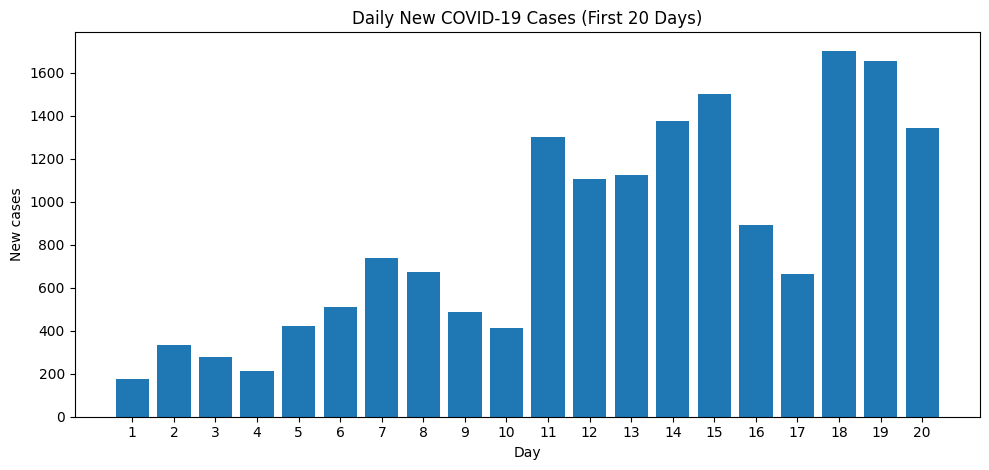

In [53]:
# Task 8 – COVID-19 infection statistics
# Sample variance/stdev use n-1 as the denominator; population values are also shown for comparison.
import statistics
import matplotlib.pyplot as plt

cases = [174, 335, 278, 214, 422, 513, 737, 672, 489, 412,
         1301, 1105, 1123, 1376, 1502, 894, 665, 1704, 1656, 1342]
days = list(range(1, len(cases) + 1))
print("Number of days:", len(cases))
print("Minimum:", min(cases))
print("Maximum:", max(cases))
print("Range:", max(cases) - min(cases))
print(f"Mean: {statistics.mean(cases):.2f}")
print(f"Median: {statistics.median(cases):.2f}")
print(f"Sample variance: {statistics.variance(cases):.2f}")
print(f"Sample standard deviation: {statistics.stdev(cases):.2f}")
print(f"Population variance (comparison): {statistics.pvariance(cases):.2f}")
print(f"Population standard deviation (comparison): {statistics.pstdev(cases):.2f}")

plt.figure(figsize=(10, 4.8))
plt.bar(days, cases)
plt.title("Daily New COVID-19 Cases (First 20 Days)")
plt.xlabel("Day")
plt.ylabel("New cases")
plt.xticks(days)
plt.tight_layout()
plt.savefig("outputs/task8_infection_bar_chart.png", dpi=160, bbox_inches="tight")
plt.show()
assert max(cases) - min(cases) == 1530

## Task 9 (Intro to Data Science: Rolling Two Dice)

Modify the script `RollDie.py` that we provided with this chapter's examples to simulate rolling two dice. Calculate the sum of the two values. Each die has a value from 1 to 6, so the sum of the values will vary from 2 to 12, with 7 being the most frequent sum, and 2 and 12 the least frequent. The following diagram shows the 36 equally likely possible combinations of the two dice and their corresponding sums:

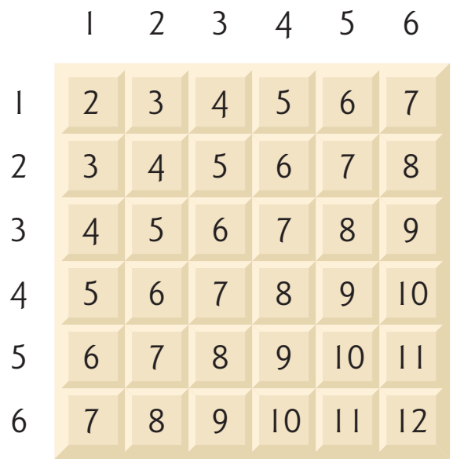
*The 36 possible combinations of two dice and their sums*

If you roll the dice 36,000 times:

- The values 2 and 12 each occur 1/36th (2.778%) of the time, so you should expect about 1000 of each.
- The values 3 and 11 each occur 2/36ths (5.556%) of the time, so you should expect about 2000 of each, and so on.

Input the number of rolls. Display a bar plot summarizing the roll frequencies. Use the Seaborn `barplot` function to show the bar plots for sample executions of 360, 36,000 and 36,000,000 rolls. For example:

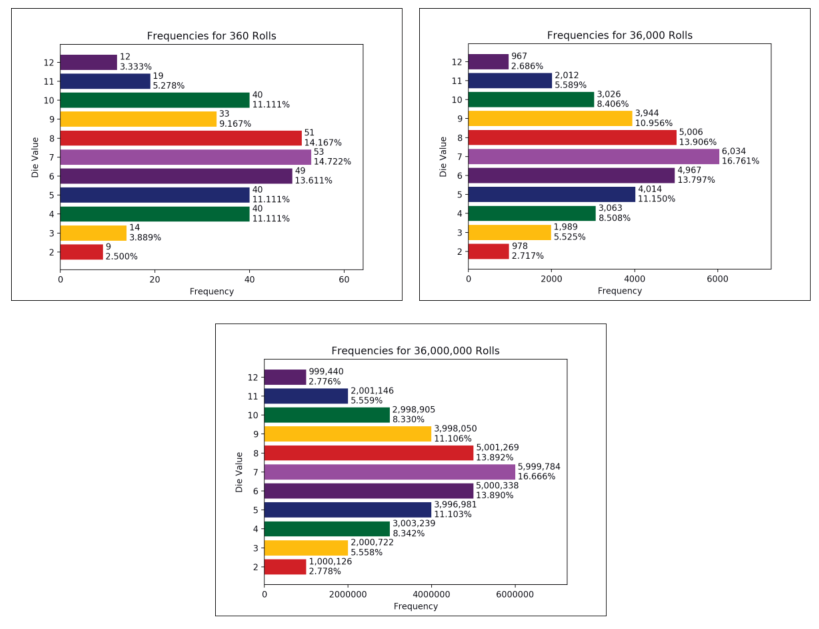
*Sample bar plots for 360, 36,000 and 36,000,000 rolls*

<font color="#C00000">**Starting point – rolling ONE die (a version of RollDie.py adapted for notebooks).** Modify it for two dice.</font>

### <font color="#0070C0">🔵 [REVISED] Task 9 · Level 3 ⭐⭐⭐ (Intermediate) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: number of rolls of two dice (e.g. 36 000). Output: the frequency of each sum 2..12.</font>
- <font color="#0070C0">**② Work an example by hand** — Sum 7 has 6/36 ways (the most); sums 2 and 12 only 1/36 ⇒ 7 appears about six times as often as 2.</font>
- <font color="#0070C0">**③ Break it down** — a count list of 13 elements (indexes 2..12) → each roll: d1 + d2 → increment the count at index = sum → print a table: sum – count – %</font>
- <font color="#0070C0">**④ Pseudo-code** (fill in the ___ blanks, then finish it in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">counts &lt;- [0] * 13
REPEAT N TIMES:
    s &lt;- randint(1, 6) + randint(1, 6)
    counts[s] &lt;- ___
FOR s FROM 2 TO 12: OUTPUT s, counts[s], counts[s]/N*100</pre>

- <font color="#0070C0">**⑤ Self-check** — The counts must add up to N.</font>

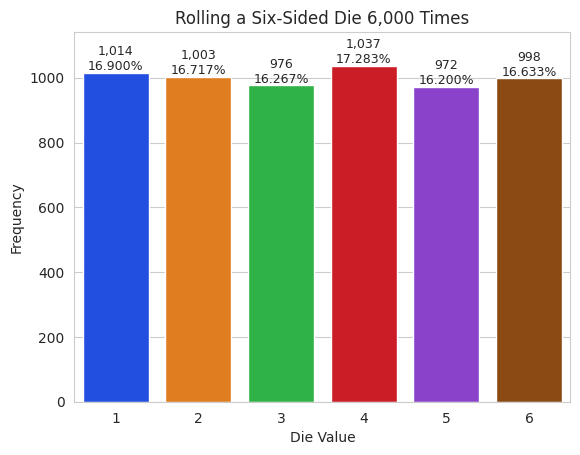

In [54]:
# [ADDED] worked example – run this cell
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

n_rolls = 6000                                  # later: int(input("Number of rolls: "))
rolls = [random.randrange(1, 7) for _ in range(n_rolls)]
values, frequencies = np.unique(rolls, return_counts=True)

sns.set_style('whitegrid')
axes = sns.barplot(x=values, y=frequencies, hue=values, palette='bright', legend=False)
axes.set_title(f'Rolling a Six-Sided Die {n_rolls:,} Times')
axes.set(xlabel='Die Value', ylabel='Frequency')
axes.set_ylim(top=max(frequencies) * 1.10)
for bar, freq in zip(axes.patches, frequencies):
    axes.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
              f'{freq:,}\n{freq / n_rolls:.3%}', ha='center', va='bottom', fontsize=9)
plt.show()

> 💡 **Tip** — **<font color="#C00000">Performance</font>**
>
> <font color="#C00000">36,000,000 rolls with a Python list comprehension takes a long time. Use NumPy instead: `die1 = np.random.randint(1, 7, size=n)`, `die2 = np.random.randint(1, 7, size=n)`, `sums = die1 + die2` – this runs in well under a second. For a horizontal chart like the sample, pass `orient='h'` (with `x=frequencies, y=values`).</font>
>


Rolls: 360
Sum | Count | Percentage
  2 |         7 |    1.944%
  3 |        19 |    5.278%
  4 |        36 |   10.000%
  5 |        42 |   11.667%
  6 |        48 |   13.333%
  7 |        55 |   15.278%
  8 |        49 |   13.611%
  9 |        46 |   12.778%
 10 |        33 |    9.167%
 11 |        17 |    4.722%
 12 |         8 |    2.222%
Counts add up to N: True

Rolls: 36,000
Sum | Count | Percentage
  2 |     1,031 |    2.864%
  3 |     2,067 |    5.742%
  4 |     2,851 |    7.919%
  5 |     3,890 |   10.806%
  6 |     4,967 |   13.797%
  7 |     6,029 |   16.747%
  8 |     5,057 |   14.047%
  9 |     4,112 |   11.422%
 10 |     2,972 |    8.256%
 11 |     2,031 |    5.642%
 12 |       993 |    2.758%
Counts add up to N: True



Rolls: 36,000,000
Sum | Count | Percentage
  2 |   998,170 |    2.773%
  3 | 1,999,747 |    5.555%
  4 | 3,001,204 |    8.337%
  5 | 4,001,076 |   11.114%
  6 | 4,999,813 |   13.888%
  7 | 5,999,655 |   16.666%
  8 | 4,999,401 |   13.887%
  9 | 3,998,152 |   11.106%
 10 | 2,999,892 |    8.333%
 11 | 2,001,197 |    5.559%
 12 | 1,001,693 |    2.782%
Counts add up to N: True


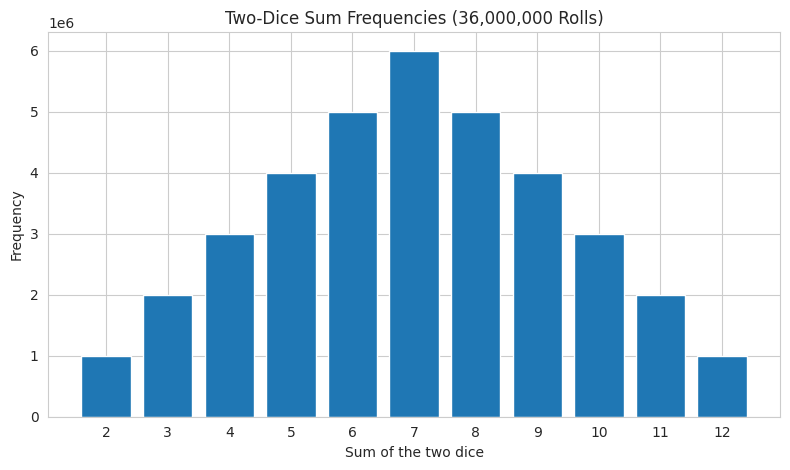

In [55]:
# Task 9 – Rolling two dice
# Simulate 360, 36,000 and 36,000,000 rolls with NumPy in chunks to limit memory use.
# Pseudocode: for each roll, sum two values 1..6; increment counts[sum]; verify count total = N.
import numpy as np
import matplotlib.pyplot as plt


def simulate_two_dice(n_rolls, rng, chunk_size=1_000_000):
    counts = np.zeros(13, dtype=np.int64)  # use indexes 2..12
    remaining = n_rolls
    while remaining > 0:
        current = min(chunk_size, remaining)
        die1 = rng.integers(1, 7, size=current, dtype=np.int8)
        die2 = rng.integers(1, 7, size=current, dtype=np.int8)
        sums = die1 + die2
        counts += np.bincount(sums, minlength=13)
        remaining -= current
    return counts

rng = np.random.default_rng(2026)
all_results = {}
for n_rolls in (360, 36_000, 36_000_000):
    counts = simulate_two_dice(n_rolls, rng)
    all_results[n_rolls] = counts
    print(f"\nRolls: {n_rolls:,}")
    print("Sum | Count | Percentage")
    for total in range(2, 13):
        print(f"{total:>3} | {counts[total]:>9,} | {counts[total] / n_rolls * 100:>8.3f}%")
    print("Counts add up to N:", int(counts[2:13].sum()) == n_rolls)

# Plot the largest simulation result.
plot_counts = all_results[36_000_000][2:13]
plt.figure(figsize=(8, 4.8))
plt.bar(range(2, 13), plot_counts)
plt.title("Two-Dice Sum Frequencies (36,000,000 Rolls)")
plt.xlabel("Sum of the two dice")
plt.ylabel("Frequency")
plt.xticks(range(2, 13))
plt.tight_layout()
plt.savefig("outputs/task9_two_dice_36000000.png", dpi=160, bbox_inches="tight")
plt.show()

## <font color="#C00000">Additional Exercises</font>

### <font color="#C00000">Task 10 – Matrix operations with 2-D lists</font>

<font color="#C00000">Without NumPy, write functions `transpose(m)`, `add(m1, m2)` and `multiply(m1, m2)` for matrices stored as lists of lists. Use nested loops for `add` and a list comprehension with `zip(*m)` for `transpose`. Test with A = [[1, 2, 3], [4, 5, 6]] and B = [[7, 8], [9, 10], [11, 12]]; A × B must be [[58, 64], [139, 154]]. Print matrices row by row with right-aligned numbers.</font>

### <font color="#0070C0">🔵 [REVISED] Task 10 · Level 4 ⭐⭐⭐⭐ (Advanced / Challenge) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: matrices (nested lists). Output: transpose, add, multiply.</font>
- <font color="#0070C0">**② Work an example by hand** — A (2×3) × B (3×2) = C (2×2); C[0][0] = 1×7 + 2×9 + 3×11 = 58.</font>
- <font color="#0070C0">**③ Break it down** — transpose: `[list(r) for r in zip(*m)]` → add: loop over rows, columns (sizes must match) → multiply: C[i][j] = Σ_k A[i][k]·B[k][j] → print row by row, right-aligned</font>
- <font color="#0070C0">**④ Pseudo-code** (only the SKELETON is given – write the details yourself in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">FUNCTION multiply(A, B):
    C &lt;- matrix rows(A) x cols(B) of 0
    FOR i, FOR j, FOR k:
        C[i][j] &lt;- C[i][j] + A[i][k] * B[k][j]
    RETURN C</pre>

- <font color="#0070C0">**⑤ Self-check** — Check: A×B = [[58, 64], [139, 154]]; check the condition cols(A) = rows(B).</font>

In [56]:
# Task 10 – Matrix operations with 2-D lists (optional challenge)
# No NumPy is used. transpose uses a list comprehension and zip(*m); add uses nested loops.
def transpose(m):
    if not m:
        return []
    return [list(row) for row in zip(*m)]

def add(m1, m2):
    if len(m1) != len(m2) or any(len(r1) != len(r2) for r1, r2 in zip(m1, m2)):
        raise ValueError("Matrices must have the same dimensions for addition.")
    result = []
    for i in range(len(m1)):
        row = []
        for j in range(len(m1[i])):
            row.append(m1[i][j] + m2[i][j])
        result.append(row)
    return result

def multiply(m1, m2):
    if not m1 or not m2 or len(m1[0]) != len(m2):
        raise ValueError("Number of columns in the first matrix must equal rows in the second.")
    rows, inner, cols = len(m1), len(m2), len(m2[0])
    result = [[0 for _ in range(cols)] for _ in range(rows)]
    for i in range(rows):
        for j in range(cols):
            for k in range(inner):
                result[i][j] += m1[i][k] * m2[k][j]
    return result

def print_matrix(m, title):
    print(title)
    for row in m:
        print(" ".join(f"{value:>6}" for value in row))

A = [[1, 2, 3], [4, 5, 6]]
B = [[7, 8], [9, 10], [11, 12]]
print_matrix(A, "A:")
print_matrix(transpose(A), "transpose(A):")
print_matrix(add(A, [[10, 20, 30], [40, 50, 60]]), "A + D:")
product = multiply(A, B)
print_matrix(product, "A x B:")
assert product == [[58, 64], [139, 154]]

A:
     1      2      3
     4      5      6
transpose(A):
     1      4
     2      5
     3      6
A + D:
    11     22     33
    44     55     66
A x B:
    58     64
   139    154


### <font color="#C00000">Task 11 – Balanced brackets (list as a stack)</font>

<font color="#C00000">A **stack** is last-in, first-out (LIFO): push with `append`, pop with `pop()`. Write `is_balanced(expr)` that returns `True` if every `(`, `[` and `{` in a string is closed in the correct order. Test with `"(a[b]{c})"` → True, `"([)]"` → False, `"((x)"` → False.</font>

### <font color="#0070C0">🔵 [REVISED] Task 11 · Level 3 ⭐⭐⭐ (Intermediate) — Analysis → Algorithm</font>

- <font color="#0070C0">**① Understand the problem** — Input: an expression string. Output: True if every ( [ { is closed in the correct order.</font>
- <font color="#0070C0">**② Work an example by hand** — "([)]": open ( then [ ; at ) the top of the stack is [ ⇒ mismatch ⇒ False.</font>
- <font color="#0070C0">**③ Break it down** — stack = empty list → opening bracket: push → closing bracket: stack empty or top does not match ⇒ False → at the end: the stack must be empty</font>
- <font color="#0070C0">**④ Pseudo-code** (fill in the ___ blanks, then finish it in the ✍️ cell)</font>

<pre style="color:#0070C0;background:#EAF3FB;padding:8px 12px;border-left:4px solid #0070C0">pairs &lt;- {&quot;)&quot;:&quot;(&quot;, &quot;]&quot;:&quot;[&quot;, &quot;}&quot;:&quot;{&quot;}
stack &lt;- []
FOR EACH ch IN expr:
    IF ch IS opening THEN stack.append(ch)
    ELSE IF ch IS closing:
        IF stack empty OR stack.pop() != pairs[ch] THEN RETURN False
RETURN (stack is empty)</pre>

- <font color="#0070C0">**⑤ Self-check** — Test the 3 examples in the task and the empty string "".</font>

In [57]:
# Task 11 – Balanced brackets (optional challenge)
# Pseudocode: push opening brackets; on closing bracket, reject empty/mismatched top; stack must end empty.
def is_balanced(expr: str) -> bool:
    pairs = {')': '(', ']': '[', '}': '{'}
    stack = []
    for ch in expr:
        if ch in '([{':
            stack.append(ch)
        elif ch in pairs:
            if not stack or stack.pop() != pairs[ch]:
                return False
    return len(stack) == 0

for expression in ["(a[b]{c})", "([)]", "((x)", "", "[]{}()", "[(])", "]"]:
    print(repr(expression), "->", is_balanced(expression))
assert is_balanced("(a[b]{c})") is True
assert is_balanced("([)]") is False
assert is_balanced("((x)") is False
assert is_balanced("") is True

'(a[b]{c})' -> True
'([)]' -> False
'((x)' -> False
'' -> True
'[]{}()' -> True
'[(])' -> False
']' -> False


In [58]:
# Task 11 – Additional self-checks
# This cell reuses is_balanced from the previous cell and adds extra edge cases.
test_cases = {
    "(a[b]{c})": True,
    "([)]": False,
    "((x)": False,
    "": True,
    "no brackets": True,
    "{[()()]}": True,
    "{[(])}": False,
    "((()))": True,
}
for expression, expected in test_cases.items():
    actual = is_balanced(expression)
    print(f"{expression!r}: expected={expected}, actual={actual}")
    assert actual == expected

'(a[b]{c})': expected=True, actual=True
'([)]': expected=False, actual=False
'((x)': expected=False, actual=False
'': expected=True, actual=True
'no brackets': expected=True, actual=True
'{[()()]}': expected=True, actual=True
'{[(])}': expected=False, actual=False
'((()))': expected=True, actual=True


## Submission note – student details

- **Student:** Nguyễn Viết Huy
- **Student ID:** ITDSIU24021
- **Class / group:** IT149IU – Group 01
- **Course:** Fundamentals of Programming (Python)
- **AI assistance:** ChatGPT was used to help interpret the task instructions, draft/debug code, and verify outputs. The student should review and understand the solutions before submission.


# 6. Submission Instructions

## What to submit

1. **Source code folder (/codes/)** – each task should be implemented in a separate `.py` file:

```text
codes/
├── Task1.py
├── Task2.py
├── Task3.py
├── Task4.py
└── ...
```

Each file must contain a header comment with student info:

```python
# Student Name:
# Student ID:
# Course: Fundamentals of Programming (FoP)
# Lab 5 – Task X
# Date:
# Description: pseudocode for the task
```

2. **Lab report (FoP_Lab5_Report.docx or .pdf)** – your report must include: cover page (name, student ID, course, semester, submission date); Tasks 1–<font color="#C00000">9 (10–11 optional)</font>; summary: what you learned.
3. The final submission is compressed into one ZIP file <font color="#C00000">(or one folder / GitHub repository)</font> named `IT149IU_Lab5_FullName_StudentID`.

## <font color="#C00000">How to submit (Google Form)</font>

<font color="#C00000">All labs are submitted through **one shared Google Form**. Submit a **link** to a folder or repository that contains your work.</font>

<font color="#C00000">**Step 1 – Organize your work** in one folder named `IT149IU_Lab5_FullName_StudentID` (e.g. `IT149IU_Lab5_NguyenVanAn_ITITIU24001`):</font>

<font color="#C00000">*(added)*</font>
```text
IT149IU_Lab5_FullName_StudentID/
├── FoP_Lab5_FullName_StudentID.ipynb
├── codes/
│   ├── Task1.py
│   └── ...
├── outputs/
│   ├── task1_output.png
│   └── ...
├── FoP_Lab5_Report.pdf
└── README.md
```

- <font color="#C00000">the **notebook** – completed, with all cells executed;</font>
- <font color="#C00000">**codes/** – one `.py` file per task, each starting with the header comment;</font>
- <font color="#C00000">**outputs/** – screenshots that clearly show input and output;</font>
- <font color="#C00000">the **lab report** (.docx or .pdf) and a **README.md** (name, student ID, how to run, notes).</font>

<font color="#C00000">**Step 2 – Upload the folder** using ONE of these options:</font>

1. <font color="#C00000">**GitHub (recommended):** create a repository (e.g. `IT149IU-FoP-Labs`, one sub-folder per lab), push your files and make the repository *Public* (or add the instructor as a collaborator).</font>
2. <font color="#C00000">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</font>
3. <font color="#C00000">**Google Colab only:** *Share* → *Anyone with the link – Viewer* → *Copy link* (use this only if all work is inside the notebook).</font>

<font color="#C00000">*(added)*</font>
```bash
# GitHub from the command line (first time)
git init
git add .
git commit -m "Lab 5 – FullName – StudentID"
git branch -M main
git remote add origin https://github.com/<your-username>/IT149IU-FoP-Labs.git
git push -u origin main
# later labs: git add . ; git commit -m "Lab N" ; git push
```

<font color="#C00000">**Step 3 – Submit the link in the Google Form**</font>

| <font color="#C00000">Item</font> | <font color="#C00000">Details</font> |
|---|---|
| <font color="#C00000">Submission form for **Lab 5** (Lab number pre-selected)</font> | <font color="#C00000">[Open the Lab 5 submission form](https://docs.google.com/forms/d/e/1FAIpQLSfCz6lyUsunGqohV90ijKKRqbGljc4b9GRj3K-ExsIJu5WOJA/viewform?usp=pp_url&entry.1269823331=Lab+5)</font> |
| <font color="#C00000">Short link (choose "Lab 5" in the form)</font> | <font color="#C00000">https://forms.gle/aHqDLDZ6YUyzoYVv8</font> |
| <font color="#C00000">Fields to fill in</font> | <font color="#C00000">Full name · Student ID · Class/Group · Lab number · Submission type · Submission link</font> |
| <font color="#C00000">Deadline</font> | <font color="#C00000">End of the lab week – Sunday 23:59 (unless the instructor announces another date)</font> |

<font color="#C00000">**Before you press Submit – checklist**</font>

- <font color="#C00000">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</font>
- <font color="#C00000">Every task has code, output (screenshot or cell output) and, where requested, pseudocode.</font>
- <font color="#C00000">Each `.py` file starts with the header comment (name, ID, course, lab, task, date, description).</font>
- <font color="#C00000">The link opens in a private/incognito browser window (sharing permission is correct).</font>
- <font color="#C00000">You may re-submit (edit your response) before the deadline; the last submission is graded.</font>

> 📌 **Note** — **<font color="#C00000">Grading guide (per lab)</font>**
>
> | <font color="#C00000">Criterion</font> | <font color="#C00000">Weight</font> |
> |---|---|
> | <font color="#C00000">Correctness of programs (all required tasks)</font> | <font color="#C00000">50%</font> |
> | <font color="#C00000">Pseudocode / algorithm and explanation</font> | <font color="#C00000">15%</font> |
> | <font color="#C00000">Code quality (names, comments, functions, input validation)</font> | <font color="#C00000">15%</font> |
> | <font color="#C00000">Output evidence (screenshots / executed notebook)</font> | <font color="#C00000">10%</font> |
> | <font color="#C00000">Extensions and challenge tasks</font> | <font color="#C00000">10%</font> |
>

> ⚠️ **Common mistakes** — **<font color="#C00000">Academic integrity</font>**
>
> <font color="#C00000">Discuss ideas with classmates, but write your own code. Copied submissions receive zero for all students involved. If you use an AI assistant, state which tool and for which part in the *Notes* field of the form and in your README.</font>
>